# Built without being asked – the Data Trust Center
HVIA gave 22 app ideas (PDF pages 2–23). Before building dashboards that look good, we asked:
**which of these ideas can this data honestly support?** Building a nice chart on a random column would give the manager a wrong decision.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

files = pd.read_pickle('../clean/cottonil_clean.pkl')

# colours: blue = main, grey = context, orange = the ONE thing each chart wants you to look at
BLUE, ORANGE, AQUA, GREY, LIGHT, INK = '#2a78d6', '#eb6834', '#1baf7a', '#b5b4ae', '#b9d3f2', '#52514e'
plt.rcParams.update({'font.size': 10.5, 'axes.titlesize': 12.5, 'axes.titleweight': 'bold', 'axes.edgecolor': '#d6d5d0',
                     'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK, 'figure.dpi': 110})


def style(ax, title, ylabel=None):
    """Title = the insight, light grid, no box."""
    ax.set_title(title, loc='left', pad=12)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    ax.grid(axis='y', color='#ecebe7'); ax.set_axisbelow(True)
    if ylabel:
        ax.set_ylabel(ylabel)


def save(fig, name):
    fig.savefig(f'../outputs/charts/{name}.png', dpi=150, bbox_inches='tight')


def full_years(d, col='fy'):
    """Complete fiscal years only: FY2019 → FY2026 (Oct–Sep)."""
    return d[(d[col] >= 2019) & (d[col] <= 2026)]


M = lambda x: f'{x / 1e6:,.1f}M'

import sys
sys.path.insert(0, '..')
from core import analytics as A
from core import forecast as F
c = files

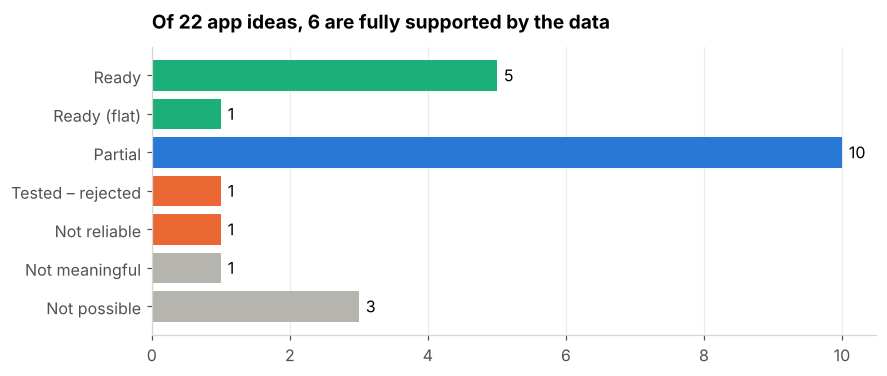

,page,idea,status,why,unlock_with
0,2,Executive Dashboard,Ready,"Sales, margin, growth and seasonality are consistent and close to the cent.",—
1,3,Sales Performance Intelligence,Ready,"Real signals: growth, Nov–Dec and Mar–May peaks, Thu–Sat, category mix.",—
2,4,Branch Performance Optimization,Not meaningful,All 80 branches sell within ±5%; 7% of orders before opening.,"Real branch sales, traffic, size (m²), opening dates"
3,5,Inventory & Warehouse Intelligence,Partial,Stock is flat for 8 years; 9.3M pieces not accounted for.,"Physical stock count, transfer receipts"
4,6,Customer Segmentation & Loyalty,Partial,19% of orders have no customer; one ID shops in ~7 branches; age/gender random.,Loyalty ID (phone) at the till
5,7,Demand Forecasting & Product Planning,Ready,Built: AI forecast 21% more accurate than last year’s same month.,—
6,8,Supply Chain & Logistics Visibility,Partial,"Statuses never close (in transit 6%, partial 33%); delivery days random.","Carrier scans, receipt dates"
7,9,Procurement & Supplier Analytics,Partial,Quantities ~100× sales; supplier types and lead times random.,"Confirmed purchase units, supplier master"
8,10,Returns & Quality Control,Partial,"Return rate is real (~1.6%), reasons are random (20% each).","Return reason form, QC defects"
9,11,Sustainability & ESG Analytics,Not possible,"No energy, water, carbon or material data at all.","Utility bills, material sourcing data"


In [2]:
r = A.readiness()
order = ['Ready', 'Ready (flat)', 'Partial', 'Tested – rejected', 'Not reliable', 'Not meaningful', 'Not possible']
cnt = r.status.value_counts().reindex(order).dropna()
fig, ax = plt.subplots(figsize=(8.5, 3.4))
colors = {'Ready': AQUA, 'Ready (flat)': AQUA, 'Partial': BLUE, 'Tested – rejected': ORANGE, 'Not reliable': ORANGE, 'Not meaningful': GREY, 'Not possible': GREY}
ax.barh(cnt.index[::-1], cnt.values[::-1], color=[colors[s] for s in cnt.index[::-1]])
for i, v in enumerate(cnt.values[::-1]):
    ax.text(v + 0.1, i, str(int(v)), va='center')
style(ax, f"Of 22 app ideas, {int(cnt.get('Ready', 0) + cnt.get('Ready (flat)', 0))} are fully supported by the data")
ax.grid(axis='x', color='#ecebe7'); ax.grid(axis='y', visible=False)
save(fig, 'trust_readiness')
r

In [3]:
dq = pd.read_csv('../outputs/data_quality_report.csv')
r.to_csv('../outputs/readiness_22_ideas.csv', index=False, encoding='utf-8-sig')
print('data quality issues by severity:', dq.severity.value_counts().to_dict())
dq[dq.severity == 'Unreliable'][['table', 'issue', 'evidence']]

data quality issues by severity: {'Unreliable': 9, 'High': 8, 'Medium': 6, 'Business': 5}


,table,issue,evidence
7,sales_orders,All branches sell almost the same,"store orders per branch 4,699 – 5,011"
8,delivery_shipments,"""Delayed"" status is not linked to delivery time","428 'Delayed' delivered in ≤1 day; 13,512 'on time' took 7 days"
9,delivery_shipments,Delivery time is the same for every governorate,3.93 – 4.05 days (Cairo = Aswan)
11,sales_payments,"Every payment is on the order day, even cash on delivery",100% same day
12,purchase_orders,"""Partial receipt"" never closes","33% partial in every year, even 2018"
13,inventory_transfers,"""In transit"" never closes","6% in transit + 2% partial, every year since 2018"
16,employees,Salary does not depend on the job,"avg salary by role 11,539 – 12,487 EGP; area manager < cashier"
22,import_shipments,Import freight does not depend on container or country,"40FT avg 6,171 USD vs 20FT 6,138 USD"
26,sales_returns,Return reasons are spread evenly (random),"5 reasons, each 20%–20%"


In [4]:
A.data_requests()[['priority', 'area', 'request']]

,priority,area,request
0,High,Purchasing,"What unit do purchase orders use (piece, dozen, kg)? 42M pieces a year vs 0.6M sold."
1,High,Inventory,Physical stock count in 5 branches: 9.3M pieces sent are neither sold nor on shelf.
2,High,Customers,"Capture a customer ID (phone) on every order – 19% have none, even online."
3,High,HR,"Real org chart and full payroll: 40 branches without a manager, payroll covers ≤225 of 640."
4,High,Marketing,One marketing ledger: 11.8M in expenses vs 219.5M in campaigns.
5,Medium,Branches,"Confirm branch opening dates: 38,040 orders are dated before opening."
6,Medium,Delivery,"Carrier scan dates: delivery time and ""Delayed"" are random today."
7,Medium,Imports,What do import rows represent (450M USD vs 0.84B EGP sales)? Add quantity and SKU.
8,Medium,Returns,A return-reason form: today each reason is exactly 20%.
9,Medium,Factories,Production data per factory (nothing links to the 6 factories).


### Why this matters
- The manager sees **which numbers to trust** before acting on them.
- Every "not possible" idea comes with the exact data that would unlock it → a data roadmap, not a dead end.
- Same honesty as rejecting the churn model: we show what works, what does not, and why.